In [1]:
import os
import torch
import torch.distributions as dist
import torch.nn as nn
from typing import List
from tqdm import tqdm
from torch.utils.tensorboard import SummaryWriter
from utils import load_mnist_dataset, flatten_image, unflatten_image, view_image
from unet import get_timestep_embedding, UNet

import matplotlib.pyplot as plt
import numpy as np


In [2]:
# Create the "Img" folder if it does not exist
if not os.path.exists('imgs'):
    os.makedirs('imgs')

In [2]:
#load_mnist_dataset()
trainY, testY = load_mnist_dataset()

In [4]:
len(trainY)

60000

In [5]:
trainY[0].shape

torch.Size([784])

In [6]:
28*28

784

In [3]:
def unflatten_data(vector, shape=(28, 28)):
    """
    Function to unflatten an image
    :param vector: Flattened image tensor
    :param shape: Target shape
    :return: Unflattened image tensor
    """
    return vector.view(-1, 1, *shape)

def sample_batch(trainY, batch_size, device):
    indices = torch.randperm(len(trainY))[:batch_size]
    data = torch.stack([trainY[i] for i in indices]).to(device)
    data = unflatten_data(data)  # Reshape to (batch_size, 1, 28, 28)
    return torch.nn.functional.interpolate(data, size=(32, 32))

def save_samples(diffusion_model, nb_images, n_batch):
    samples = diffusion_model.sampling(n_samples=nb_images, use_tqdm=False)
    plt.figure(figsize=(17, 17))
    for i in range(nb_images):
        plt.subplot(9, 9, 1 + i)
        plt.axis('off')
        plt.imshow(samples[i].squeeze(0).clip(0, 1).data.cpu().numpy(), cmap='gray')
    plt.savefig(f'imgs/samples_epoch_{n_batch}.png')
    plt.close()


In [9]:
mean = torch.tensor([0.0, 0.0])  # Example mean for a 2D Gaussian
covariance_matrix = torch.tensor([[1.0, 0.5], [0.5, 1.0]])  # Example covariance matrix


In [10]:
sample_multivariate_gaussian(mean=mean, covariance=covariance_matrix, num_samples=2)

tensor([[ 0.6389,  0.8871],
        [-0.3440,  0.3592]])

In [11]:
t_sample = torch.rand(10,device='cuda', dtype=torch.float32)
t_sample.shape
t_sample = t_sample.unsqueeze(1).unsqueeze(2).unsqueeze(3)  # Shape: (10, 1, 1, 1)

In [12]:
get_timestep_embedding(torch.tensor([10]),32)

tensor([[-0.5440, -0.7653,  0.2113,  0.9999,  0.7563,  0.4477,  0.2486,  0.1355,
          0.0735,  0.0398,  0.0215,  0.0117,  0.0063,  0.0034,  0.0018,  0.0010,
         -0.8391,  0.6437, -0.9774, -0.0141,  0.6542,  0.8942,  0.9686,  0.9908,
          0.9973,  0.9992,  0.9998,  0.9999,  1.0000,  1.0000,  1.0000,  1.0000]])

In [13]:
get_timestep_embedding(torch.tensor([0.1]),32)[0][0]

tensor(0.0998)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


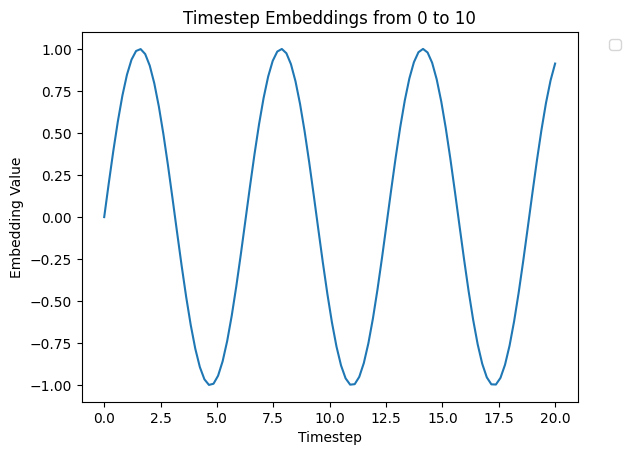

In [14]:
tt_list = torch.linspace(0, 20, steps=100)

# Get the embeddings for each timestep
embeddings = [get_timestep_embedding(torch.tensor([t]), 32)[0][0].detach().numpy() for t in tt_list]

# Convert list of embeddings to numpy array for plotting
embeddings = np.array(embeddings)


plt.plot(tt_list.numpy(), embeddings)

plt.xlabel('Timestep')
plt.ylabel('Embedding Value')
plt.title('Timestep Embeddings from 0 to 10')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


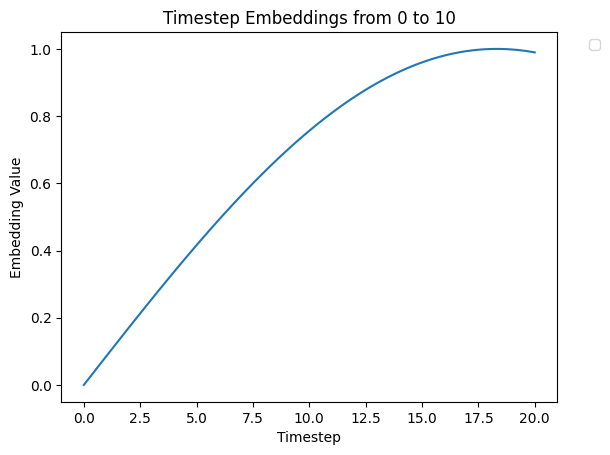

In [15]:
embeddings = [get_timestep_embedding(torch.tensor([t]), 32)[0][4].detach().numpy() for t in tt_list]

# Convert list of embeddings to numpy array for plotting
embeddings = np.array(embeddings)


plt.plot(tt_list.numpy(), embeddings)

plt.xlabel('Timestep')
plt.ylabel('Embedding Value')
plt.title('Timestep Embeddings from 0 to 10')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [17]:
test_sample_y = sample_batch(trainY, batch_size=10, device='cuda')

In [18]:
x_sample = torch.randn(test_sample_y.shape, device='cuda')
x_sample.shape

torch.Size([10, 1, 32, 32])

In [19]:
prod = torch.randn(test_sample_y.shape, device='cuda')*t_sample
prod.shape

torch.Size([10, 1, 32, 32])

In [20]:
test_sample_y.shape

torch.Size([10, 1, 32, 32])

In [21]:
test_sample_y[0][0][23]

tensor([-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,  0.8902,  0.9843,
         0.9843,  0.9843,  0.5451, -0.9137, -0.9451, -0.6784, -0.0353,  0.9843,
         1.0000,  1.0000,  0.9843,  0.9843,  0.3804, -0.8667, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000],
       device='cuda:0')

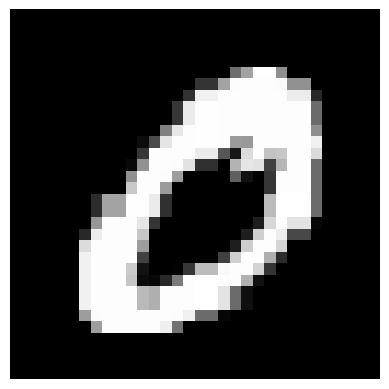

In [22]:
view_image(test_sample_y.cpu()[0])

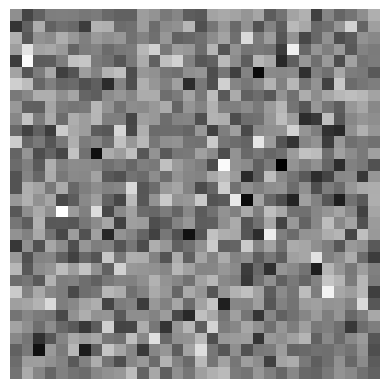

In [23]:
view_image(x_sample.cpu()[0])

In [24]:
get_timestep_embedding(torch.tensor([0.4]), embedding_dim=12)

tensor([[3.8942e-01, 6.3353e-02, 1.0047e-02, 1.5924e-03, 2.5238e-04, 4.0000e-05,
         9.2106e-01, 9.9799e-01, 9.9995e-01, 1.0000e+00, 1.0000e+00, 1.0000e+00]])

In [5]:
class SimpleBrownianBridgeDiffusion:

    def __init__(self, T: float, model: nn.Module, device: str, trainY: List):
        self.T = T
        self.function_approximator = model.to(device)
        self.device = device
        self.trainY = trainY

        self._EPS = 0.0000001


    def train(self, batch_size, optimizer):
        """
        Corollary 2.7 implementation
        """

        # sample target images y
        y = sample_batch(self.trainY, batch_size, self.device)
        # sample random times from [0,T)
        t = torch.rand(batch_size,device=self.device, dtype=torch.float32)*self.T
        # Unsqueeze t to align dimensions
        t = t.unsqueeze(1).unsqueeze(2).unsqueeze(3)  # Shape: (batch_size, 1, 1, 1)
        # sample x as independent gaussians 
        x = torch.randn(y.shape, device=self.device)
        # compute E_t
        E = x + (y-x)*t/self.T
        # compute V_t
        V = t*(self.T-t)/self.T
        # compute xi_t sampling 
        xi = E + torch.randn(y.shape, device=self.device)*torch.sqrt(V)
        # Take one gradient descent step
        # The input to function_approximator must be 4D: (batch_size, channels, height, width)
        # t is a list of times [batch_size] (hence squeeze)
        img_predicted = self.function_approximator(xi, t.squeeze())
        loss = nn.functional.mse_loss(y, img_predicted)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        return loss.item()

    @torch.no_grad()
    def sampling(self, n_samples=1, image_channels=1, img_size=(32, 32), n_steps=100,
                 use_tqdm=True):
        """
        Corollary 2.9 implementation
        """
        # create n_steps t
        # messing about with n_steps as small eps gets rounded away
        t_values = torch.linspace(0, self.T, steps=n_steps + 1, device=device)* (self.T - self._EPS) / self.T

        # sample x
        delta = (self.T - self._EPS)/ n_steps
        x = torch.randn((n_samples, image_channels, img_size[0], img_size[1]),
                        device=self.device)

        xi_t = x
        Z_t = x
        
        progress_bar = tqdm if use_tqdm else lambda x: x
        for idx, t in enumerate(progress_bar(t_values[:-1])):
            t = torch.tensor(t, device=self.device) 
            inv_lambda = 1/(self.T - t)
            # mu_t = x; Sigma_tt = t
            Z = x + torch.randn(x.shape, device=self.device)*torch.sqrt(t)
            dZ = torch.randn(x.shape, device=device)*torch.sqrt(torch.tensor(delta))
            # need a list of repeated t with len same as n_samples
            t_list = [t for _ in range(n_samples)]
            #xi = xi_t + inv_lambda*(self.function_approximator(xi_t, torch.stack(t_list)) - xi_t )*delta + (Z - Z_t)
            xi = xi_t + inv_lambda*(self.function_approximator(xi_t, torch.stack(t_list)) - xi_t )*delta 
            #+ dZ

            xi_t = xi
            #Z_t = Z
        return xi_t


In [6]:
device = 'cuda'
batch_size = 128 
model = UNet()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
# Initialize TensorBoard writer
writer = SummaryWriter(log_dir='runs/batch_128_T_1_A')
diffusion_model = SimpleBrownianBridgeDiffusion(1., model, device, trainY)

In [7]:
# Training
for n_batch in tqdm(range(40000)):
    loss = diffusion_model.train(batch_size, optimizer)
    if isinstance(loss, torch.Tensor):
        loss = loss.item()

    # Log the loss to TensorBoard
    writer.add_scalar('Loss/train', loss, n_batch)

# Close the writer when done
writer.close()

  2%|▏         | 960/40000 [05:47<3:55:29,  2.76it/s]


KeyboardInterrupt: 

In [111]:
# Save sampled images every 2000 epochs
#if (n_batch + 1) % 1000 == 0:
#    save_samples(diffusion_model, nb_images=81, n_batch=n_batch + 1)

In [16]:
samples = diffusion_model.sampling(n_samples=1, use_tqdm=True, n_steps=1000)

  0%|          | 0/1000 [00:00<?, ?it/s]/tmp/ipykernel_341167/2277425475.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t, device=self.device)
100%|██████████| 1000/1000 [00:15<00:00, 66.27it/s]


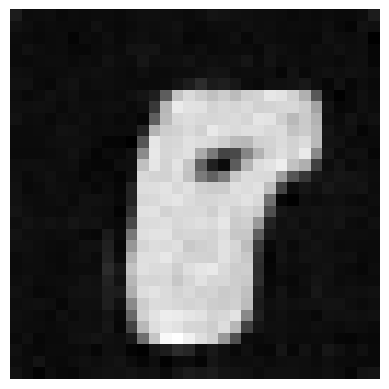

In [17]:
view_image(samples.cpu()[0])

In [102]:
torch.rand(10,device='cuda', dtype=torch.float32)

tensor([0.5543, 0.7002, 0.1347, 0.7712, 0.9482, 0.1833, 0.5135, 0.2389, 0.5964,
        0.0672], device='cuda:0')

In [143]:
test_sample_y[0].shape

torch.Size([1, 32, 32])

In [144]:
xi_t.shape

torch.Size([1, 1, 32, 32])

In [147]:
tt_samp = torch.linspace(0, 10, steps=10, device=device)

In [148]:
tt_samp

tensor([ 0.0000,  1.1111,  2.2222,  3.3333,  4.4444,  5.5556,  6.6667,  7.7778,
         8.8889, 10.0000], device='cuda:0')

In [150]:
test_mod_img = model(test_sample_y,tt_samp)

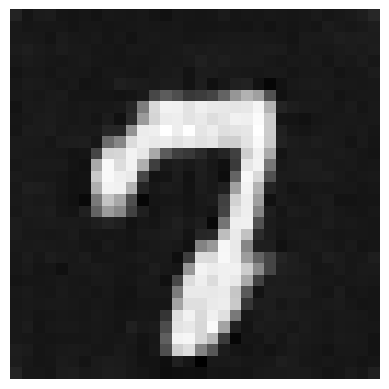

In [154]:
view_image(test_mod_img.detach().cpu().numpy()[9])

In [296]:
T =1
# sample target images y
y = sample_batch(trainY, 1, device)
        # sample random times from [0,T)
t = torch.rand(1,device=device, dtype=torch.float32)*T
t = torch.tensor(T*0.9,device=device, dtype=torch.float32)
        # Unsqueeze t to align dimensions
#t = t.unsqueeze(1).unsqueeze(2).unsqueeze(3)  # Shape: (batch_size, 1, 1, 1)
        # sample x as independent gaussians 
x = torch.randn(y.shape, device=device)
        # compute E_t
E = x + (y-x)*t/T
        # compute V_t
V = t*(T-t)/T
        # compute xi_t sampling 
xi = E + torch.randn(y.shape, device=device)*torch.sqrt(V)

tensor(0.9000, device='cuda:0')
tensor(0.9000, device='cuda:0')
torch.Size([])


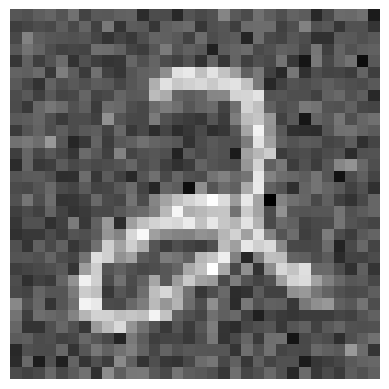

In [297]:
print(t.squeeze())
print(t/T)
print((t/T).shape)
view_image(xi.detach().cpu().numpy()[0])

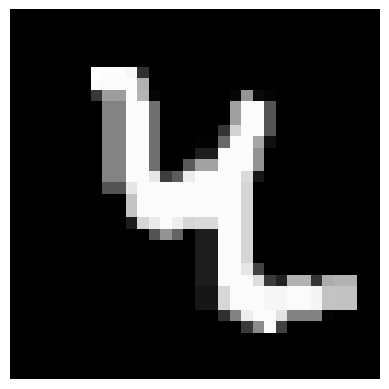

In [295]:
view_image(y.detach().cpu().numpy()[0])

In [163]:
t.shape

torch.Size([128, 1, 1, 1])

In [436]:
@torch.no_grad()
def tes_sampling(n_samples=1, image_channels=1, img_size=(32, 32), n_steps=1000, use_tqdm=True, T=10., EPS=0.0000001, device='cuda' ):
    """
    Corollary 2.9 implementation
    """
    # create n_steps t
    t_values = torch.linspace(0, T, steps=n_steps + 1, device=device)* (T - EPS) / T
    yy = sample_batch(trainY, 1, device)

        # sample x
    delta = (T - EPS)/ n_steps
    x = torch.randn((n_samples, image_channels, img_size[0], img_size[1]),
                        device=device)

    xi_t = x
    Z_t = x
    zero_tensor = torch.zeros_like(x)
    #Z_t = zero_tensor
        
    progress_bar = tqdm if use_tqdm else lambda x: x
    for idx, t in enumerate(progress_bar(t_values[:-1])):
        #t = torch.tensor(t, device=self.device) 
        inv_lambda = 1/(T - t)
        # mu_t = x; Sigma_tt = t
        #Z = x + torch.randn(x.shape, device=device)*torch.sqrt(t_values[idx+1])
        dZ = torch.randn(x.shape, device=device)*torch.sqrt(torch.tensor(delta))
        # need a list of repeated t with len same as n_samples
        t_list = [t for _ in range(n_samples)]
        #xi = xi_t + inv_lambda*(model(xi_t, torch.stack(t_list)) - xi_t )*delta + (Z - Z_t)
        xi = xi_t + inv_lambda*(yy - xi_t )*delta 
        #+ dZ 

        xi_t = xi
        #Z_t = Z 
        #view_image(xi_t.cpu()[0])
    return xi_t, t_values, delta, inv_lambda, yy

In [437]:
xi_t, t_values, delta, inv_lambda, yy = tes_sampling(1, n_steps=1000, T=1)

100%|██████████| 1000/1000 [00:00<00:00, 7842.64it/s]


0.0009999999
tensor([0.0000, 0.0010, 0.0020,  ..., 0.9980, 0.9990, 1.0000], device='cuda:0')


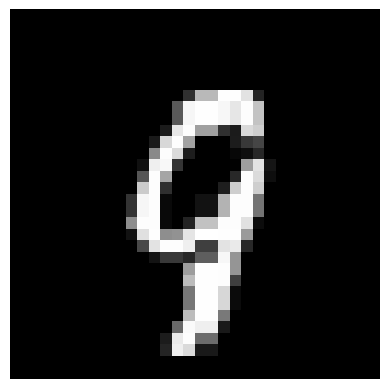

In [438]:
print(delta)
print(t_values)
view_image(xi_t.cpu()[0])

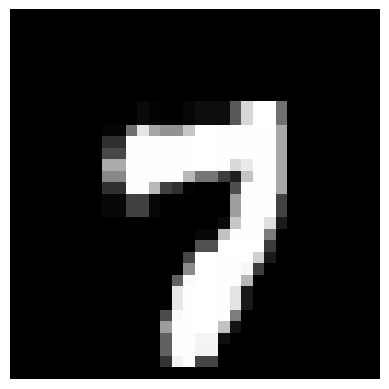

In [398]:
view_image(yy.cpu()[0])